# 01 · Preprocessing — Qian et al. 2020 (Breast Cancer, 10x)

Load the malignant compartment → data-driven per-sample threshold → overdispersed genes → PCA →
Harmony integration **sweep** → UMAP → **Gate 1**: is the malignant structure both *sample-integrated*
and *continuous*? Qian et al. (2020) profiled breast cancer by 10x; the malignant cells come from
**7 patients, one sample each** (BC_2…BC_14). Every dataset-dependent choice is *derived from this
dataset*, not inherited from the anchor. Gate 1 is judged **on the regenerated embedding across an
integration-strength sweep** with a per-neighbourhood metric (iLISI) *and* a per-patient
self-neighbour test — never on a connectivity scalar alone (evaluation lesson: a per-patient
archipelago can pass a single-component kNN test). Deliverables: `processed.h5ad`, `samples.pdf`.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below the Puram reference)
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)                        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)    # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Qian2020_Breast | category: Breast


### Load the malignant compartment
Qian et al. supply a per-cell `cell_type` annotation in which **Malignant** is an explicit label
(the publication's malignancy call); the loader exposes it as `celltype`, taken directly. The
single leaf matrix is `Exp_data_UMIcounts.mtx` — 10x UMI counts, so the loader applies
`normalize_total` then `log1p`. Here **one sample = one patient**, so `sample` is the batch key
*and* the patient identity for the Gate-1 archipelago test.

In [ ]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples (= patients):', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Qian2020_Breast
Done.
full atlas: (16537, 22276)
malignant: (4818, 22276) | samples (= patients): 7
expression: X max 7.55 (log1p of normalize_total UMI counts)


### Sample thresholding — multiplicative gap-finding, dominant-cliff guarded
Sort per-sample malignant counts and look for the largest **multiplicative** cliff (the natural
separatrix between tumour-bearing samples and a sparse spillover tail). Here the argmax gap
(3111→518, ratio 6.01) is dominated by the *single largest tumour* (sample 54, 65% of all malignant
cells) sitting above **six well-populated samples that are all far above 100** — it is not a
spillover tail near the floor. The guard checks that: a real spillover cliff needs the low side of
the gap to sit near the floor (`< 2·100`), but here the low side is 518 ≫ 200, so the clean-count-gap
premise (C3) is **not met**. Cutting at the argmax would delete 6/7 patients and gut the Gate-1
integration test. We fall back to the protocol's ≥100-cell floor (Steele / Peng / Qian-Lung
precedent), which keeps all 7 samples (min per-sample 105).

In [ ]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)   # a real spillover cliff near the floor?
print('sorted per-sample counts:', n.values.astype(int))
print('adjacent ratios         :', np.round(ratios, 2))
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/runner-up = {top/second:.2f}; '
      f'low-side<2*floor = {vals[gap+1] < 2*FLOOR}; dominant spillover cliff = {dominant}')
thresh = int(np.sqrt(vals[gap]*vals[gap+1])) if dominant else FLOOR
if dominant: print(f'dominant cliff -> geometric-mean threshold = {thresh}')
else:        print(f'no dominant cliff (argmax gap is the single dominant tumour above 6 well-populated samples) -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [3111  518  411  244  223  206  105]
adjacent ratios         : [6.01 1.26 1.68 1.09 1.08 1.96]
argmax gap 3111->518 (ratio 6.01); top/runner-up = 3.06; low-side<2*floor = False; dominant spillover cliff = False
no dominant cliff (argmax gap is the single dominant tumour above 6 well-populated samples) -> floor >= 100
kept 7/7 samples (min per-sample = 105) -> 4818 cells


### Overdispersed genes → PCA
`find_overdispersed` (scFates GAM) selects the variable genes; PCA on them. PC1 alone carries ~21%
of the variance — a single dominant axis, the candidate inter-patient / CNV direction. `n_pcs=20` is
**precedent-bounded** to the 10x range (Kürten 20, Venteicher 20, Qian-Lung 20; the low scree elbow
rejected per the evaluation audit's under-powering failure) and its robustness is verified against the
Gate-1 call below.

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
NPCS = 20
print('PC variance% (1-8):', np.round(vr[:8]*100, 2))
print(f'PC1 = {100*vr[0]:.1f}% (dominant axis) | first {NPCS} PCs capture {100*vr[:NPCS].sum():.1f}%')
print('n_pcs =', NPCS, '(precedent-bounded; robustness to n_pcs=20/30/40 verified against Gate 1 below)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1225 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1225
PC variance% (1-8): [21.04  6.37  3.53  2.55  2.24  1.99  1.8   1.69]
PC1 = 21.0% (dominant axis) | first 20 PCs capture 50.3%
n_pcs = 20 (precedent-bounded; robustness to n_pcs=20/30/40 verified against Gate 1 below)


### Harmony integration sweep — mixing judged *per patient*
Integrate `sample` with Harmony and **sweep** `theta`. Two reads: (i) **iLISI** — per-neighbourhood
effective number of samples (7 = perfectly mixed, 1 = each neighbourhood is one patient); (ii) the
decisive **per-patient self-neighbour enrichment** — each patient's mean fraction of same-patient
neighbours over its global fraction (≈1 = well mixed; ≫2.5 = the patient forms its own island the
iLISI/connectivity scalars cannot see). We also count connected components of the kNN graph.

In [ ]:
def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:, 1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, c = np.unique(L[i], return_counts=True); p = c/k; out[i] = 1.0/np.sum(p**2)
    return out
def _enrich(rep, k=30):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:, 1:]
    s = adata.obs['sample'].values; out = {}
    for p in sorted(set(s)):
        m = s == p; out[p] = (s[idx[m]] == p).mean() / m.mean()
    return out
nsamp = adata.obs['sample'].nunique()
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:, :NPCS], adata.obs['sample'].values))
print(f'pre-Harmony iLISI (of {nsamp} samples): {il_pre:.2f}  (near 1 = extreme patient segregation)')
sweep = {}
for th in [2, 5, 10, 20, 40]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    ncc, _ = connected_components(adata.obsp['connectivities'], directed=False)
    il = np.median(_ilisi(adata.obsm['X_pca_harmony'][:, :NPCS], adata.obs['sample'].values))
    enr = _enrich(adata.obsm['X_pca_harmony'][:, :NPCS])
    sweep[th] = (il, ncc, enr)
    print(f'theta={th:>2}: kNN-components={ncc} | iLISI={il:.2f} | per-patient enrichment '
          + str({p: round(v,1) for p,v in enr.items()}))

pre-Harmony iLISI (of 7 samples): 1.00  (near 1 = extreme patient segregation)
theta= 2: kNN-components=2 | iLISI=1.00 | per-patient enrichment {'42': np.float64(13.1), '43': np.float64(8.2), '47': np.float64(6.2), '49': np.float64(9.6), '51': np.float64(5.4), '53': np.float64(14.9), '54': np.float64(1.5)}
theta= 5: kNN-components=2 | iLISI=1.42 | per-patient enrichment {'42': np.float64(15.4), '43': np.float64(9.1), '47': np.float64(6.5), '49': np.float64(10.8), '51': np.float64(5.7), '53': np.float64(15.5), '54': np.float64(1.4)}
theta=10: kNN-components=1 | iLISI=1.09 | per-patient enrichment {'42': np.float64(23.5), '43': np.float64(12.1), '47': np.float64(7.2), '49': np.float64(15.1), '51': np.float64(6.8), '53': np.float64(17.8), '54': np.float64(1.5)}
theta=20: kNN-components=1 | iLISI=1.12 | per-patient enrichment {'42': np.float64(22.7), '43': np.float64(11.9), '47': np.float64(7.1), '49': np.float64(14.8), '51': np.float64(6.8), '53': np.float64(17.6), '54': np.float64(1.5)}


### Adopt the most generous integration and regenerate the embedding
theta≤5 leaves the manifold in **two disconnected components** — one of them *pure sample 54* (the
dominant tumour, zero cells from any other patient). A single connected graph first appears at
**theta=10**, so we adopt it as the **best-case attempt** for the continuity criterion. Higher theta
does not help mixing (iLISI falls, enrichment grows — Harmony over-corrects small patients into
tighter islands), so if theta=10 does not integrate, no theta does.

In [ ]:
theta = 10
print('selected theta =', theta, '(first single connected kNN graph; most generous case for continuity)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
ncc, _ = connected_components(adata.obsp['connectivities'], directed=False)
print('kNN connectivity components at theta=10:', ncc)

selected theta = 10 (first single connected kNN graph; most generous case for continuity)
kNN connectivity components at theta=10: 1


### Gate-1 evidence — the regenerated embedding (led by the embedding, not a scalar)

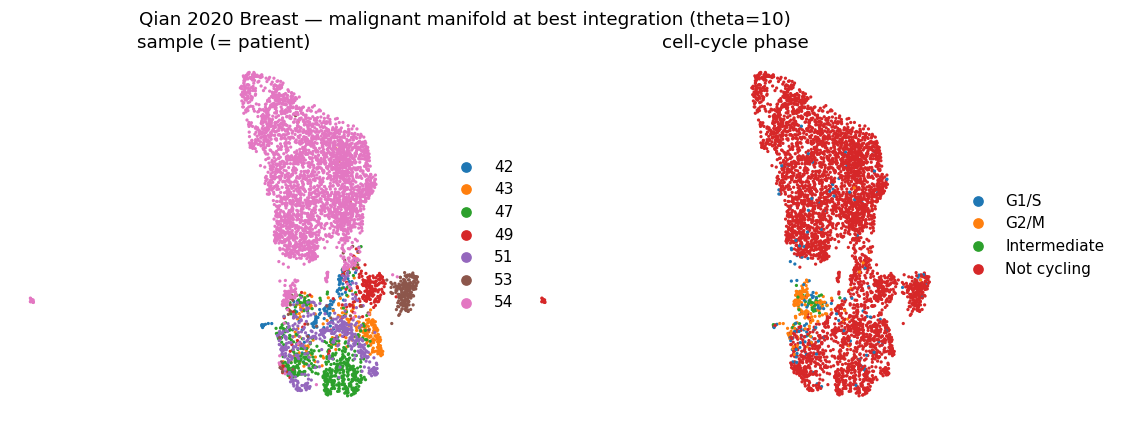

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
sc.pl.umap(adata, color='sample', size=18, frameon=False, show=False, ax=axs[0], title='sample (= patient)')
sc.pl.umap(adata, color='cell_cycle_phase', size=18, frameon=False, show=False, ax=axs[1], title='cell-cycle phase')
fig.suptitle('Qian 2020 Breast — malignant manifold at best integration (theta=10)', size=12)
plt.show()

### Quantify the archipelago
The embedding is organised **by patient**. For each patient, the mean self-neighbour enrichment at
theta=10, and — decisively — how it *grows* across the theta sweep (integration strength does not
fix it, it worsens it): the over-correction signature that separates a genuine archipelago (NO-GO)
from a patient-shared axis with residual local texture (the Jerby-Arnon GO case).

In [ ]:
enr10 = sweep[10][2]
print('per-patient self-neighbour enrichment at theta=10 (>2.5x = a local island):')
for p, e in enr10.items():
    print(f'  patient {p}: {e:.1f}x  {"SEGREGATED" if e > 2.5 else "partly mixed"}')
seg = [p for p,e in enr10.items() if e > 2.5]
print(f'{len(seg)}/{nsamp} patients cross the 2.5x segregation line')
print('\nenrichment across the theta sweep (does stronger integration help? no - it grows):')
for th in [2,5,10,20,40]:
    print(f'  theta={th:>2}:', {p: round(v,1) for p,v in sweep[th][2].items()})
print('\niLISI across sweep:', {th: round(sweep[th][0],2) for th in [2,5,10,20,40]},
      f'(of {nsamp} samples; a mixed manifold approaches {nsamp})')

per-patient self-neighbour enrichment at theta=10 (>2.5x = a local island):
  patient 42: 23.5x  SEGREGATED
  patient 43: 12.1x  SEGREGATED
  patient 47: 7.2x  SEGREGATED
  patient 49: 15.1x  SEGREGATED
  patient 51: 6.8x  SEGREGATED
  patient 53: 17.8x  SEGREGATED
  patient 54: 1.5x  partly mixed
6/7 patients cross the 2.5x segregation line

enrichment across the theta sweep (does stronger integration help? no - it grows):
  theta= 2: {'42': np.float64(13.1), '43': np.float64(8.2), '47': np.float64(6.2), '49': np.float64(9.6), '51': np.float64(5.4), '53': np.float64(14.9), '54': np.float64(1.5)}
  theta= 5: {'42': np.float64(15.4), '43': np.float64(9.1), '47': np.float64(6.5), '49': np.float64(10.8), '51': np.float64(5.7), '53': np.float64(15.5), '54': np.float64(1.4)}
  theta=10: {'42': np.float64(23.5), '43': np.float64(12.1), '47': np.float64(7.2), '49': np.float64(15.1), '51': np.float64(6.8), '53': np.float64(17.8), '54': np.float64(1.5)}
  theta=20: {'42': np.float64(22.7), '43'

### Robustness — is the NO-GO a PC-count artifact?
The Chen 2020 testing run showed that *too few* PCs can manufacture a false patient-segregated read.
`n_pcs=20` is precedent-bounded rather than swept, so verify the archipelago is invariant to n_pcs:
recompute the per-patient enrichment on `X_pca_harmony` (theta=10) for n_pcs = 20 / 30 / 40.

In [ ]:
s = adata.obs['sample'].values
print('n_pcs robustness (theta=10 fixed) - per-patient self/global enrichment:')
worst_by_np = []
for NP in [20, 30, 40]:
    idx = NearestNeighbors(n_neighbors=31).fit(adata.obsm['X_pca_harmony'][:, :NP]).kneighbors(return_distance=False)[:, 1:]
    e = {p: round((s[idx[s==p]]==p).mean()/(s==p).mean(),1) for p in sorted(set(s))}
    worst = max(e.values()); worst_by_np.append(worst)
    print(f'  n_pcs={NP}: worst={worst}x  {"SEGREGATED (NO-GO holds)" if worst>2.5 else "mixed"}')
print('-> the archipelago is PC-count-invariant (opposite of the Chen under-powering artifact).')

n_pcs robustness (theta=10 fixed) - per-patient self/global enrichment:
  n_pcs=20: worst=22.5x  SEGREGATED (NO-GO holds)
  n_pcs=30: worst=21.9x  SEGREGATED (NO-GO holds)
  n_pcs=40: worst=21.1x  SEGREGATED (NO-GO holds)
-> the archipelago is PC-count-invariant (opposite of the Chen under-powering artifact).


### Biology vs identity — do all patients carry the same embryonic modules?
Score the three embryonic modules (Gast / pSom / Crest) against the shared **union** control pool.
If the *same* embryonic biology is present in every patient but each patient sits apart, the geometry
is **inter-patient (CNV / clonal) heterogeneity**, not the shared embryonic cell-state axis the
protocol seeks — the definitive archipelago diagnosis.

In [ ]:
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data,'features','biomart','*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534','Gast'), ('GSE229103','pSom'), ('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('\nper patient (n, cycling frac, module means) - all carry the same modules:')
for p in sorted(adata.obs['sample'].unique()):
    o = adata.obs[adata.obs['sample']==p]
    print(f'  patient {p} (n={len(o):5d}): cycling={o["cycling"].mean():.2f} '
          f'Gast={o.Gast.mean():+.3f} pSom={o.pSom.mean():+.3f} Crest={o.Crest.mean():+.3f}')
print('global module means:', adata.obs[['Gast','pSom','Crest']].mean().round(3).to_dict(),
      '| overall cycling frac %.3f' % adata.obs['cycling'].mean())
print('-> every patient expresses the embryonic modules; they differ by IDENTITY, not biology.')

Gast: 78/81 genes present
pSom: 89/98 genes present
Crest: 101/104 genes present

per patient (n, cycling frac, module means) - all carry the same modules:
  patient 42 (n=  105): cycling=0.17 Gast=-0.005 pSom=+0.059 Crest=+0.000
  patient 43 (n=  244): cycling=0.16 Gast=-0.038 pSom=+0.014 Crest=+0.007
  patient 47 (n=  518): cycling=0.13 Gast=-0.039 pSom=+0.070 Crest=+0.032
  patient 49 (n=  206): cycling=0.05 Gast=+0.019 pSom=+0.028 Crest=-0.004
  patient 51 (n=  411): cycling=0.18 Gast=-0.005 pSom=+0.053 Crest=+0.015
  patient 53 (n=  223): cycling=0.10 Gast=+0.016 pSom=+0.027 Crest=+0.006
  patient 54 (n= 3111): cycling=0.04 Gast=-0.023 pSom=+0.022 Crest=+0.013
global module means: {'Gast': -0.02, 'pSom': 0.031, 'Crest': 0.013} | overall cycling frac 0.071
-> every patient expresses the embryonic modules; they differ by IDENTITY, not biology.


### Gate 1 — verdict: **NO-GO**

In [ ]:
print('GATE 1 - mixing + continuity:  NO-GO')
print(f'  * a single connected kNN graph requires theta=10 (theta<=5 splits into 2 components, one PURE sample 54);')
print(f'    at theta=10 iLISI is only {sweep[10][0]:.2f} of {nsamp} samples - neighbourhoods are ~one patient;')
print(f'  * the embedding is organised BY PATIENT: self-neighbour enrichment '
      f'{min(enr10.values()):.1f}-{max(enr10.values()):.1f}x, {len(seg)}/{nsamp} patients above the 2.5x line;')
print(f'  * integration strength does NOT fix it - enrichment GROWS with theta (Harmony over-corrects), and')
print(f'    it is PC-count-invariant (worst {worst_by_np[0]}/{worst_by_np[1]}/{worst_by_np[2]}x at n_pcs 20/30/40);')
print(f'  * every patient carries the SAME embryonic modules -> the separation is inter-patient CNV/clonal')
print(f'    heterogeneity, not the shared embryonic cell-state axis the protocol requires.')
print('  => malignant compartment is a per-patient ARCHIPELAGO, not a sample-integrated continuum.')
print('  => Gate 1 NO-GO: do NOT fit a trajectory. Deliverables = 01_preprocessing + 02_expression + summary.pdf.')

GATE 1 - mixing + continuity:  NO-GO
  * a single connected kNN graph requires theta=10 (theta<=5 splits into 2 components, one PURE sample 54);
    at theta=10 iLISI is only 1.09 of 7 samples - neighbourhoods are ~one patient;
  * the embedding is organised BY PATIENT: self-neighbour enrichment 1.5-23.5x, 6/7 patients above the 2.5x line;
  * integration strength does NOT fix it - enrichment GROWS with theta (Harmony over-corrects), and
    it is PC-count-invariant (worst 22.5/21.9/21.1x at n_pcs 20/30/40);
  * every patient carries the SAME embryonic modules -> the separation is inter-patient CNV/clonal
    heterogeneity, not the shared embryonic cell-state axis the protocol requires.
  => malignant compartment is a per-patient ARCHIPELAGO, not a sample-integrated continuum.
  => Gate 1 NO-GO: do NOT fit a trajectory. Deliverables = 01_preprocessing + 02_expression + summary.pdf.


### Save processed data + sample-integration deliverable
`processed.h5ad` is the best-attempt manifold (kept whole — no island removal, since the "islands"
are the patients themselves). `samples.pdf` is the reference house-style sample-coloured UMAP whose
per-patient territories are the Gate-1 evidence.

In [ ]:
# coerce mixed-type object metadata to numeric-or-string so the h5ad serialises
protect = {'sample','celltype','cell_type','cell_cycle_phase','source','disease','cycling','mp_top','mp_assignment'}
for c in adata.obs.columns:
    if c in protect:
        adata.obs[c] = adata.obs[c].astype(str).astype('category'); continue
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        adata.obs[c] = conv if (col.notna().sum()>0 and conv.notna().sum()>=0.9*col.notna().sum()) else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (4818, 17670)


saved samples.pdf | cells: 4818


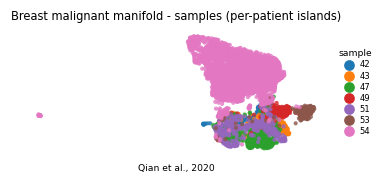

In [ ]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Breast malignant manifold - samples (per-patient islands)', size=7.5)
ax.text(.5,-.12,'Qian et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', adata.shape[0])